Lab 1

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from skimage import data

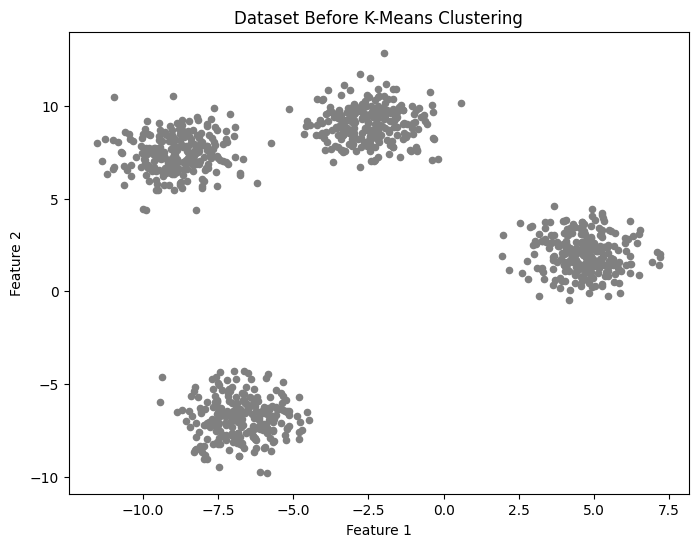

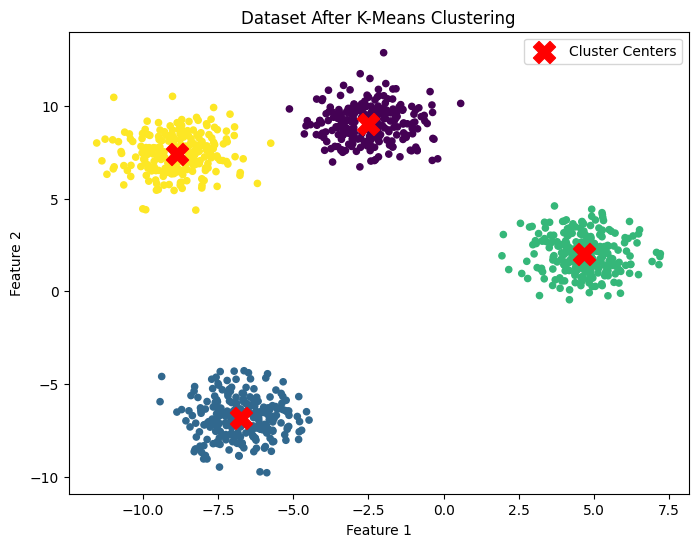

In [ ]:
# Generate the dataset
X, y = make_blobs(
    n_samples=1000,
    centers=4,
    random_state=42
)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], color='gray', s=20)
plt.title("Dataset Before K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.savefig("kmeans_data_before.png")
plt.show()


kmeans = KMeans(
    n_clusters=4,
    random_state=42
)

labels = kmeans.fit_predict(X)


centers = kmeans.cluster_centers_


plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    cmap='viridis',
    s=20
)


plt.scatter(
    centers[:, 0],
    centers[:, 1],
    color='red',
    marker='X',
    s=250,
    label='Cluster Centers'
)

plt.title("Dataset After K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()

plt.savefig("kmeans_data_after.png")
plt.show()


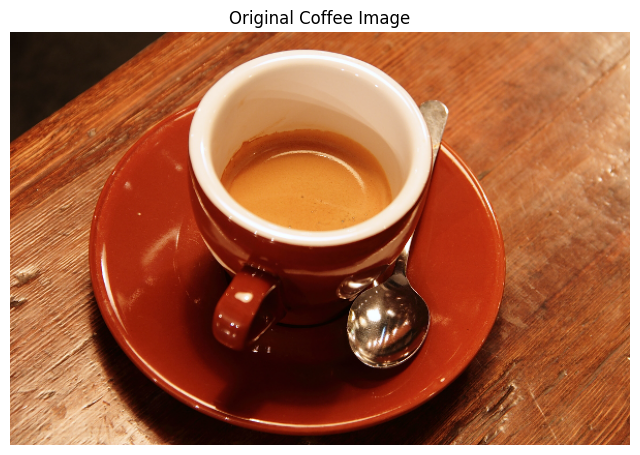

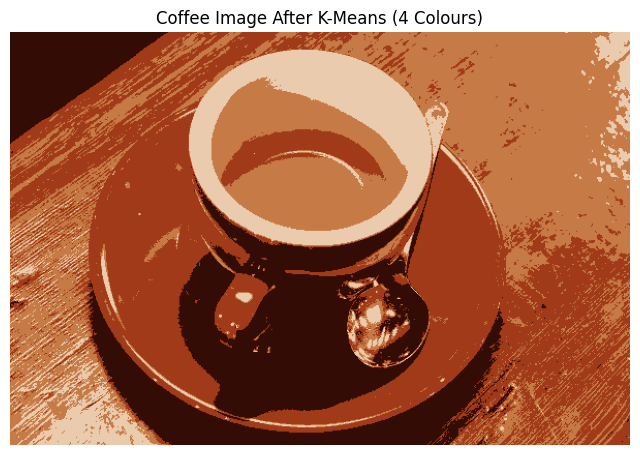

In [ ]:

# Dataset 2: Real Image

image = data.coffee()

plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.title("Original Coffee Image")
plt.axis("off")
plt.savefig("kmeans_image_before.png")
plt.show()


original_shape = image.shape

pixels = image.reshape(-1, 3)

kmeans_img = KMeans(
    n_clusters=4,
    random_state=42
)

labels = kmeans_img.fit_predict(pixels)

centers = kmeans_img.cluster_centers_

compressed_pixels = centers[labels]

compressed_image = compressed_pixels.reshape(original_shape)

compressed_image = np.uint8(compressed_image)

plt.figure(figsize=(8, 6))
plt.imshow(compressed_image)
plt.title("Coffee Image After K-Means (4 Colours)")
plt.axis("off")
plt.savefig("kmeans_image_after.png")
plt.show()


Lab 2:

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.cluster import SpectralClustering
from sklearn.cluster import spectral_clustering
from sklearn.feature_extraction import image as sk_image
from skimage import data
from skimage.transform import rescale
from skimage.filters import gaussian

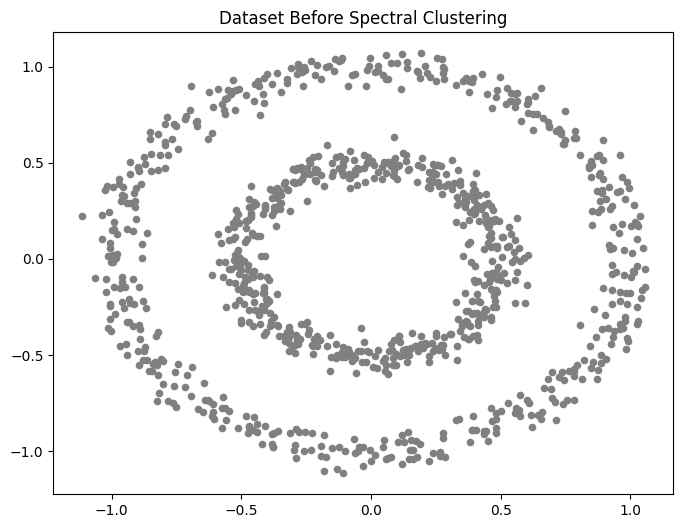

/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_spectral_embedding.py:329: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


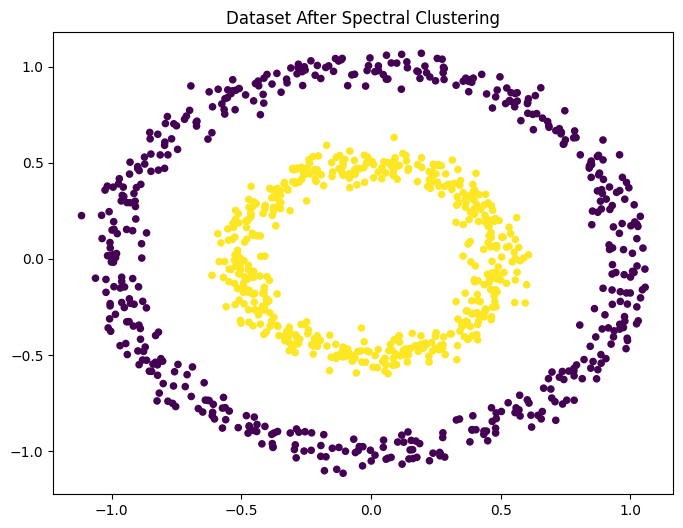

In [ ]:
# Step 1: Generate the dataset

X, y = make_circles(
    n_samples=1000,
    factor=0.5,
    noise=0.05,
    random_state=42
)

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], color='gray', s=20)
plt.title("Dataset Before Spectral Clustering")
plt.savefig("spectral_data_before.png")
plt.show()

spectral = SpectralClustering(
    n_clusters=2,
    affinity="nearest_neighbors",
    random_state=42
)

labels = spectral.fit_predict(X)
plt.figure(figsize=(8, 6))
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    cmap="viridis",
    s=20
)

plt.title("Dataset After Spectral Clustering")
plt.savefig("spectral_data_after.png")
plt.show()

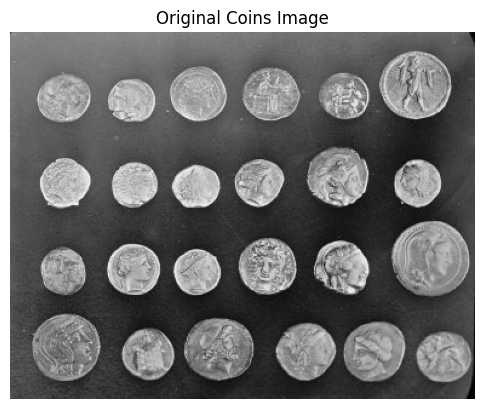

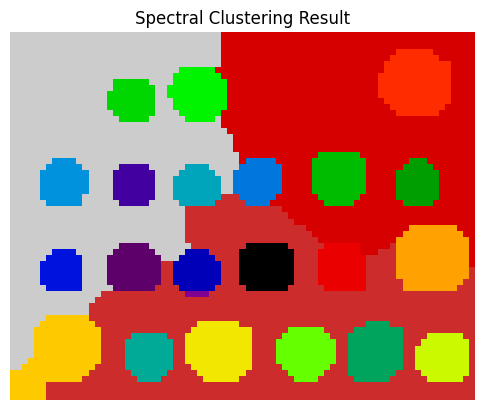

In [ ]:

# Dataset 2: Real Image (Coins)
coins = data.coins()

plt.figure(figsize=(6,6))
plt.imshow(coins, cmap="gray")
plt.title("Original Coins Image")
plt.axis("off")
plt.savefig("spectral_image_before.png")
plt.show()

coins_smooth = gaussian(coins, sigma=2)

coins_small = rescale(coins_smooth, 0.2)

graph = sk_image.img_to_graph(coins_small)

graph.data = np.exp(-10 * graph.data / graph.data.std())

labels = spectral_clustering(
    graph,
    n_clusters=25,
    assign_labels="discretize",
    random_state=42
)

labels = labels.reshape(coins_small.shape)

plt.figure(figsize=(6,6))
plt.imshow(labels, cmap="nipy_spectral")
plt.title("Spectral Clustering Result")
plt.axis("off")
plt.savefig("spectral_image_after.png")
plt.show()